# 13 - Hyperparameter Tuning (model 1 & model 2)

A **validation-based** hyperparameter search.

**Method (the important part):** every candidate config is trained and scored on
the **validation** set. Only the **single winning config** is finally evaluated on
the **test** set - so the test score stays honest.

- **Part A - GRU grid search** (cheap, the substantive one): search learning rate
  x hidden size, then refine dropout. Produces a heatmap + the chosen config.
- **Part B - Video LR sweep** (expensive, so deliberately small): a 3-point
  learning-rate sweep on a training subset, just to demonstrate the method.

Non-destructive: the tuned GRU is saved as `sequence_model_tuned.pth` and does
NOT overwrite your deployed `model23` models. Run on Colab GPU.

In [1]:
import torch, os
assert torch.cuda.is_available(), 'No GPU active. Runtime > Change runtime type > GPU, then re-run.'
print('GPU:', torch.cuda.get_device_name(0))
from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
print('Drive ready:', os.path.isdir('/content/drive/MyDrive'))
!pip install -q opencv-python-headless seaborn gdown

GPU: NVIDIA L4
Drive ready: True


In [2]:
import os
CLASSES = [
    (0, 'Short Serve', '00_Short Serve'),
    (1, 'Lift',        '02_Lift'),
    (2, 'Clear',       '12_Clear'),
    (3, 'Drop Shot',   '05_Drop Shot'),
    (4, 'Smash',       '14_Smash'),
]
NUM_CLASSES   = len(CLASSES)
DISPLAY_NAMES = [c[1] for c in CLASSES]
CLASS_FOLDERS = [c[2] for c in CLASSES]
FOLDER_TO_ID  = {c[2]: c[0] for c in CLASSES}
ID_TO_NAME    = {c[0]: c[1] for c in CLASSES}
PAD_TOKEN     = NUM_CLASSES
SEED          = 42

DRIVE       = '/content/drive/MyDrive/BadmintonFYP'
MODELS      = DRIVE + '/model23'
DATASET_ZIP = DRIVE + '/DATASET2.zip'
os.makedirs(MODELS, exist_ok=True)

NUM_FRAMES = 16; IMG = 224; BATCH = 8
IMAGENET_MEAN = [0.485, 0.456, 0.406]; IMAGENET_STD = [0.229, 0.224, 0.225]

SEQ_LEN = 4
SHUTTLESET_DIR = '/content/ShuttleSet22'
SHUTTLE_MAP = {
    '發短球': 0, '發長球': 0,
    '挑球': 1, '防守回挑': 1,
    '長球': 2, '平球': 2, '小平球': 2, '後場抽平球': 2, '防守回抽': 2,
    '切球': 3, '過度切球': 3, '過渡切球': 3, '放小球': 3, '擋小球': 3, '勾球': 3, '推球': 3,
    '殺球': 4, '點扣': 4, '撲球': 4,
}

GRU_LRS      = [5e-4, 1e-3, 2e-3]
GRU_HIDDENS  = [64, 128, 256]
GRU_DROPOUTS = [0.2, 0.3, 0.5]
GRU_EPOCHS   = 15
GRU_PATIENCE = 4
GRU_EPOCHS_FINAL = 25

VID_LRS    = [3e-4, 1e-4, 3e-5]
VID_FRAC   = 0.30
VID_EPOCHS = 4

GRU_DEFAULT = {'lr': 1e-3, 'hidden': 128, 'layers': 2, 'dropout': 0.3}
print('config ready')

config ready


## Part A - GRU grid search (learning rate x hidden, then dropout)

In [3]:
import urllib.request, zipfile, shutil, copy, itertools
import numpy as np, pandas as pd
import torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

SET_FOLDER = SHUTTLESET_DIR + '/set'
if not (os.path.isdir(SET_FOLDER) and os.listdir(SET_FOLDER)):
    url = 'https://github.com/wywyWang/CoachAI-Projects/archive/refs/heads/main.zip'; zp = '/content/coachai.zip'
    print('Downloading ShuttleSet22 ...'); urllib.request.urlretrieve(url, zp)
    with zipfile.ZipFile(zp) as z: z.extractall('/content/_ca')
    src = '/content/_ca/CoachAI-Projects-main/CoachAI-Challenge-IJCAI2023/ShuttleSet22'
    if os.path.exists(SHUTTLESET_DIR): shutil.rmtree(SHUTTLESET_DIR)
    shutil.move(src, SHUTTLESET_DIR)
print('set folder present:', os.path.isdir(SET_FOLDER))

def parse_rallies(set_folder):
    rallies = []
    for match in os.listdir(set_folder):
        mp = os.path.join(set_folder, match)
        if not os.path.isdir(mp): continue
        for sf in ('set1.csv', 'set2.csv', 'set3.csv'):
            path = os.path.join(mp, sf)
            if not os.path.exists(path): continue
            try: d = pd.read_csv(path)
            except Exception: continue
            if 'rally' not in d.columns or 'type' not in d.columns: continue
            for rid, rd in d.groupby('rally'):
                shots = [SHUTTLE_MAP[t] for t in rd['type'].astype(str).str.strip() if t in SHUTTLE_MAP]
                if len(shots) >= 2: rallies.append({'match_id': match, 'shots': shots})
    return rallies
def build_windows(rallies, seq_len=SEQ_LEN):
    w = []
    for r in rallies:
        s = r['shots']
        for i in range(len(s)):
            h = s[max(0, i - seq_len):i]
            if len(h) < seq_len: h = [PAD_TOKEN] * (seq_len - len(h)) + h
            w.append({'input': h, 'target': s[i], 'match_id': r['match_id']})
    return w
def seq_split(windows, val=0.15, test=0.15, seed=SEED):
    d = pd.DataFrame(windows)
    g1 = GroupShuffleSplit(n_splits=1, test_size=val + test, random_state=seed)
    tr, tmp = next(g1.split(d, groups=d.match_id))
    dtr, dtmp = d.iloc[tr].reset_index(drop=True), d.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test / (val + test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.match_id))
    return dtr, dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)
class SequenceDataset(Dataset):
    def __init__(self, df):
        self.x = [torch.tensor(a, dtype=torch.long) for a in df['input']]
        self.y = torch.tensor(df['target'].values, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]
class ShotPredictorGRU(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, embed=32, hidden=128, layers=2, drop=0.3):
        super().__init__()
        self.emb = nn.Embedding(num_classes + 1, embed, padding_idx=PAD_TOKEN)
        self.gru = nn.GRU(embed, hidden, layers, batch_first=True, dropout=drop if layers > 1 else 0)
        self.fc = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(drop), nn.Linear(hidden, num_classes))
    def forward(self, x):
        x = self.emb(x); o, _ = self.gru(x); return self.fc(o[:, -1, :])

rallies = parse_rallies(SET_FOLDER); windows = build_windows(rallies)
sdf_train, sdf_val, sdf_test = seq_split(windows)
strain = DataLoader(SequenceDataset(sdf_train), batch_size=64, shuffle=True)
sval   = DataLoader(SequenceDataset(sdf_val),   batch_size=64)
stest  = DataLoader(SequenceDataset(sdf_test),  batch_size=64)
cnt = sdf_train['target'].value_counts().sort_index(); tot = len(sdf_train)
W = torch.tensor([tot / (NUM_CLASSES * cnt.get(i, 1)) for i in range(NUM_CLASSES)], dtype=torch.float32)
print('windows', len(windows), '| train', len(sdf_train), 'val', len(sdf_val), 'test', len(sdf_test))

@torch.no_grad()
def eval_gru(m, loader):
    m.eval(); P, L, t3, n = [], [], 0.0, 0
    for x, y in loader:
        lg = m(x.to(DEVICE)).cpu()
        P += lg.argmax(1).tolist(); L += y.tolist()
        t3 += (lg.topk(3, 1).indices == y.unsqueeze(1)).any(1).float().sum().item(); n += len(y)
    return accuracy_score(L, P), f1_score(L, P, average='macro'), t3 / n

def train_gru(lr, hidden, layers, dropout, embed=32, epochs=GRU_EPOCHS, patience=GRU_PATIENCE):
    torch.manual_seed(SEED)
    m = ShotPredictorGRU(embed=embed, hidden=hidden, layers=layers, drop=dropout).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=W.to(DEVICE)); opt = optim.Adam(m.parameters(), lr=lr)
    best, bad, best_state = 0.0, 0, None
    for ep in range(epochs):
        m.train()
        for x, y in strain:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(); loss = crit(m(x), y); loss.backward(); opt.step()
        _, vf, _ = eval_gru(m, sval)
        if vf > best: best, bad, best_state = vf, 0, copy.deepcopy(m.state_dict())
        else:
            bad += 1
            if bad >= patience: break
    m.load_state_dict(best_state)
    return m, best
print('GRU search helpers ready')

set folder present: True
windows 51173 | train 34558 val 8052 test 8563
GRU search helpers ready


lr 5e-04 | hidden  64 -> val macro-F1 0.5092
lr 5e-04 | hidden 128 -> val macro-F1 0.5239
lr 5e-04 | hidden 256 -> val macro-F1 0.5296
lr 1e-03 | hidden  64 -> val macro-F1 0.5253
lr 1e-03 | hidden 128 -> val macro-F1 0.5347
lr 1e-03 | hidden 256 -> val macro-F1 0.5372
lr 2e-03 | hidden  64 -> val macro-F1 0.5218
lr 2e-03 | hidden 128 -> val macro-F1 0.5408
lr 2e-03 | hidden 256 -> val macro-F1 0.5307

Best (lr x hidden): {'lr': 0.002, 'hidden': 128, 'val_macro_f1': 0.5408}


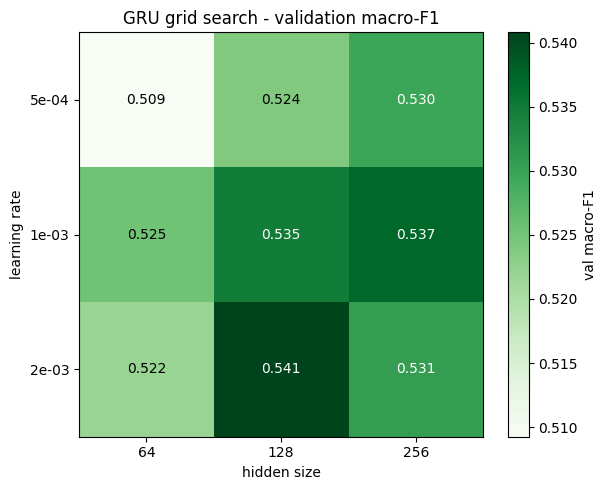

Saved heatmap to /content/drive/MyDrive/BadmintonFYP/model23/hp_gru_grid.png


In [4]:
val_grid = np.zeros((len(GRU_LRS), len(GRU_HIDDENS)))
rows = []
for i, lr in enumerate(GRU_LRS):
    for j, hid in enumerate(GRU_HIDDENS):
        _, vf = train_gru(lr, hid, layers=2, dropout=0.3)
        val_grid[i, j] = vf
        rows.append({'lr': lr, 'hidden': hid, 'val_macro_f1': round(vf, 4)})
        print('lr %.0e | hidden %3d -> val macro-F1 %.4f' % (lr, hid, vf))

best_row = max(rows, key=lambda r: r['val_macro_f1'])
print()
print('Best (lr x hidden):', best_row)

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(val_grid, cmap='Greens', aspect='auto')
ax.set_xticks(range(len(GRU_HIDDENS))); ax.set_xticklabels(GRU_HIDDENS)
ax.set_yticks(range(len(GRU_LRS))); ax.set_yticklabels(['%.0e' % l for l in GRU_LRS])
ax.set_xlabel('hidden size'); ax.set_ylabel('learning rate')
for i in range(len(GRU_LRS)):
    for j in range(len(GRU_HIDDENS)):
        ax.text(j, i, '%.3f' % val_grid[i, j], ha='center', va='center',
                color='white' if val_grid[i, j] > val_grid.mean() else 'black')
plt.colorbar(im, label='val macro-F1'); plt.title('GRU grid search - validation macro-F1')
plt.tight_layout(); plt.savefig(MODELS + '/hp_gru_grid.png', dpi=150); plt.show()
print('Saved heatmap to', MODELS + '/hp_gru_grid.png')

In [5]:
blr, bhid = best_row['lr'], best_row['hidden']
drow = []
for d in GRU_DROPOUTS:
    _, vf = train_gru(blr, bhid, layers=2, dropout=d)
    drow.append((d, vf)); print('dropout %.1f -> val macro-F1 %.4f' % (d, vf))
bestd = max(drow, key=lambda t: t[1])[0]
print('Best dropout:', bestd)

_, base_vf = train_gru(GRU_DEFAULT['lr'], GRU_DEFAULT['hidden'], GRU_DEFAULT['layers'], GRU_DEFAULT['dropout'])

best_model, best_vf = train_gru(blr, bhid, 2, bestd, epochs=GRU_EPOCHS_FINAL)
te_acc, te_f1, te_t3 = eval_gru(best_model, stest)

print()
print('==================== GRU TUNING RESULT ====================')
print('Default config : lr %.0e, hidden %d, dropout %.1f -> val macro-F1 %.4f' %
      (GRU_DEFAULT['lr'], GRU_DEFAULT['hidden'], GRU_DEFAULT['dropout'], base_vf))
print('Tuned config   : lr %.0e, hidden %d, dropout %.1f -> val macro-F1 %.4f' % (blr, bhid, bestd, best_vf))
print('Improvement on val: %+.4f macro-F1' % (best_vf - base_vf))
print('Tuned TEST     : acc %.3f | macro-F1 %.3f | top-3 %.3f' % (te_acc, te_f1, te_t3))
torch.save(best_model.state_dict(), MODELS + '/sequence_model_tuned.pth')
print('Saved tuned GRU -> ' + MODELS + '/sequence_model_tuned.pth  (model23 untouched)')

dropout 0.2 -> val macro-F1 0.5421
dropout 0.3 -> val macro-F1 0.5408
dropout 0.5 -> val macro-F1 0.5339
Best dropout: 0.2

==================== GRU TUNING RESULT ====================
Default config : lr 1e-03, hidden 128, dropout 0.3 -> val macro-F1 0.5347
Tuned config   : lr 2e-03, hidden 128, dropout 0.2 -> val macro-F1 0.5421
Improvement on val: +0.0074 macro-F1
Tuned TEST     : acc 0.548 | macro-F1 0.574 | top-3 0.971
Saved tuned GRU -> /content/drive/MyDrive/BadmintonFYP/model23/sequence_model_tuned.pth  (model23 untouched)


## Part B - Video learning-rate sweep (small, on a training subset)

The video model is expensive to train, so this is a deliberately small 3-point
**learning-rate** sweep on a subset of the data - enough to *demonstrate the
method* and pick a sensible LR. Lower `VID_FRAC` / `VID_EPOCHS` to go faster,
or skip Part B entirely.

In [6]:
import glob, cv2
import torchvision.models as models
import torchvision.transforms as transforms

EXTRACT_DIR = '/content/data'; GDRIVE_FILE_ID = ''
def has_all(d): return os.path.isdir(d) and all(os.path.isdir(os.path.join(d, f)) for f in CLASS_FOLDERS)
def find_root(base):
    for c in [base] + sorted(glob.glob(base + '/*')) + sorted(glob.glob(base + '/*/*')):
        if os.path.isdir(c) and any(os.path.isdir(os.path.join(c, f)) for f in CLASS_FOLDERS): return c
    return None
root = find_root(EXTRACT_DIR)
if root is None or not has_all(root):
    zips = [z for p in (DATASET_ZIP, DRIVE + '/*.zip', '/content/*.zip') for z in glob.glob(p)]
    zips = [z for z in zips if os.path.exists(z)]
    if not zips:
        try:
            import gdown; outp = '/content/DATASET2.zip'
            if not os.path.exists(outp): gdown.download(id=GDRIVE_FILE_ID, output=outp, quiet=False)
            if os.path.exists(outp) and os.path.getsize(outp) > 1000000: zips = [outp]
        except Exception as e: print('gdown failed:', e)
    if zips:
        if os.path.exists(EXTRACT_DIR): shutil.rmtree(EXTRACT_DIR)
        with zipfile.ZipFile(zips[0]) as z: z.extractall(EXTRACT_DIR)
        root = find_root(EXTRACT_DIR)
DATASET_DIR = root or EXTRACT_DIR
print('DATASET_DIR =', DATASET_DIR)

_norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
def load_frames(path, n=NUM_FRAMES):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened(): raise ValueError('cannot open ' + path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0: cap.release(); raise ValueError('0 frames')
    frames = []
    for i in np.linspace(0, total - 1, n, dtype=int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, fr = cap.read()
        if ok: frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        elif frames: frames.append(frames[-1].copy())
    cap.release()
    while len(frames) < n: frames.append(frames[-1].copy() if frames else np.zeros((IMG, IMG, 3), np.uint8))
    return frames[:n]
def letterbox(img, size=IMG):
    h, w = img.shape[:2]; s = min(size / h, size / w); nh, nw = int(h * s), int(w * s)
    r = cv2.resize(img, (nw, nh)); c = np.zeros((size, size, 3), np.uint8); y, x = (size - nh) // 2, (size - nw) // 2; c[y:y+nh, x:x+nw] = r; return c
class VideoClipDataset(Dataset):
    def __init__(self, df): self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        try:
            fr = load_frames(row.file_path)
            t = torch.stack([_norm(torch.from_numpy(letterbox(f).astype(np.float32)/255.0).permute(2,0,1)) for f in fr])
            return t, int(row.label_id)
        except Exception:
            return torch.zeros(NUM_FRAMES, 3, IMG, IMG), int(row.label_id)
def build_index(rootdir):
    rows = []
    for folder in CLASS_FOLDERS:
        p = os.path.join(rootdir, folder)
        if not os.path.isdir(p): continue
        lid = FOLDER_TO_ID[folder]
        for fn in os.listdir(p):
            if fn.lower().endswith('.mp4'):
                gid = fn.split('_dataset_set')[0] if '_dataset_set' in fn else fn[:19]
                rows.append({'file_path': os.path.join(p, fn), 'label_id': lid, 'group_id': gid})
    return pd.DataFrame(rows)
def vid_split(df, val=0.15, test=0.15, seed=SEED):
    g1 = GroupShuffleSplit(n_splits=1, test_size=val + test, random_state=seed)
    tr, tmp = next(g1.split(df, groups=df.group_id)); dtmp = df.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test / (val + test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.group_id))
    return df.iloc[tr].reset_index(drop=True), dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)
class TemporalPoolingResNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True):
        super().__init__()
        w = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        base = models.resnet18(weights=w)
        self.features = nn.Sequential(*list(base.children())[:-1])
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.view(b*t, c, h, w)
        x = self.features(x).view(b, t, 512).mean(dim=1)
        return self.fc(x)
def vid_class_weights(d):
    cnt = d.label_id.value_counts().sort_index(); tot = len(d)
    return torch.tensor([tot / (NUM_CLASSES * cnt.get(i, 1)) for i in range(NUM_CLASSES)], dtype=torch.float32)

dfv = build_index(DATASET_DIR)
vdf_train, vdf_val, vdf_test = vid_split(dfv)
vsub = vdf_train.groupby('label_id', group_keys=False).sample(frac=VID_FRAC, random_state=SEED).reset_index(drop=True)
vval_loader = DataLoader(VideoClipDataset(vdf_val), batch_size=BATCH, num_workers=2)
print('video train', len(vdf_train), '| sweep subset', len(vsub), '| val', len(vdf_val))

@torch.no_grad()
def vid_val_f1(m):
    m.eval(); P, L = [], []
    for x, y in vval_loader:
        P += m(x.to(DEVICE)).argmax(1).cpu().tolist(); L += y.tolist()
    return f1_score(L, P, average='macro')
print('video defs ready')

DATASET_DIR = /content/data
video train 2828 | sweep subset 849 | val 658
video defs ready


  lr 3e-04 epoch 1 -> val macro-F1 0.6787
  lr 3e-04 epoch 2 -> val macro-F1 0.7836
  lr 3e-04 epoch 3 -> val macro-F1 0.6488
  lr 3e-04 epoch 4 -> val macro-F1 0.7766
lr 3e-04 BEST val macro-F1 0.7836
  lr 1e-04 epoch 1 -> val macro-F1 0.6786
  lr 1e-04 epoch 2 -> val macro-F1 0.7817
  lr 1e-04 epoch 3 -> val macro-F1 0.8097
  lr 1e-04 epoch 4 -> val macro-F1 0.7254
lr 1e-04 BEST val macro-F1 0.8097
  lr 3e-05 epoch 1 -> val macro-F1 0.5495
  lr 3e-05 epoch 2 -> val macro-F1 0.6999
  lr 3e-05 epoch 3 -> val macro-F1 0.7366
  lr 3e-05 epoch 4 -> val macro-F1 0.7592
lr 3e-05 BEST val macro-F1 0.7592

Best video learning rate (on val subset): 1e-04 -> macro-F1 0.8097
(Your deployed model uses lr 1e-4.)


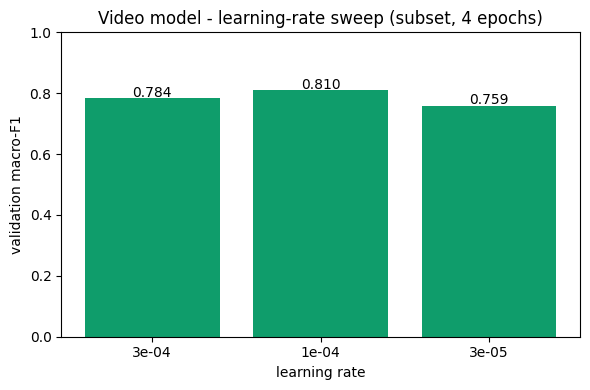

Saved chart to /content/drive/MyDrive/BadmintonFYP/model23/hp_video_lr.png


In [7]:
vsub_loader = DataLoader(VideoClipDataset(vsub), batch_size=BATCH, shuffle=True, num_workers=2)
vresults = []
for lr in VID_LRS:
    torch.manual_seed(SEED)
    m = TemporalPoolingResNet(pretrained=True).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=vid_class_weights(vsub).to(DEVICE))
    opt = optim.Adam(m.parameters(), lr=lr)
    best = 0.0
    for ep in range(VID_EPOCHS):
        m.train()
        for x, y in vsub_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(); loss = crit(m(x), y); loss.backward(); opt.step()
        vf = vid_val_f1(m); best = max(best, vf)
        print('  lr %.0e epoch %d -> val macro-F1 %.4f' % (lr, ep + 1, vf))
    vresults.append((lr, best)); print('lr %.0e BEST val macro-F1 %.4f' % (lr, best))
    del m; torch.cuda.empty_cache()

best_lr = max(vresults, key=lambda t: t[1])
print()
print('Best video learning rate (on val subset):', '%.0e' % best_lr[0], '-> macro-F1 %.4f' % best_lr[1])
print('(Your deployed model uses lr 1e-4.)')

plt.figure(figsize=(6, 4))
plt.bar(['%.0e' % l for l, _ in vresults], [v for _, v in vresults], color='#0f9d6b')
for i, (l, v) in enumerate(vresults): plt.text(i, v + 0.005, '%.3f' % v, ha='center')
plt.ylim(0, 1.0); plt.ylabel('validation macro-F1'); plt.xlabel('learning rate')
plt.title('Video model - learning-rate sweep (subset, %d epochs)' % VID_EPOCHS)
plt.tight_layout(); plt.savefig(MODELS + '/hp_video_lr.png', dpi=150); plt.show()
print('Saved chart to', MODELS + '/hp_video_lr.png')